# Initial conditions for an N-body simulation

Differentiable initial conditions for a DISCO-DJ N-body simulation.

An N-body simulation starts from one Gaussian realisation of the linear matter field. Inflation sets a single random field, the comoving curvature perturbation $\mathcal{R}$, and every species follows from it through a transfer function. DISCO-EB's solutions are per unit initial $\mathcal{R}$, so at the starting scale factor

$$
\delta_m(k, a_\mathrm{ini}) = T_m(k, a_\mathrm{ini}) \, \mathcal{R}(k), \qquad
\langle |\mathcal{R}(k)|^2 \rangle = \frac{2 \pi^2}{k^3} A_s \left(\frac{k}{k_p}\right)^{n_s - 1},
$$

and the particles move off their grid by the Zel'dovich displacement

$$
\boldsymbol{\Psi}(\boldsymbol{k}) = \frac{i \boldsymbol{k}}{k^2} \, \delta_m(k) .
$$

Lengths are in Mpc.

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from discoeb import LCDM, solve_eb

N_GRID = 64  # particles per side
BOX = 500.0  # side of the box, Mpc
A_INI = 1.0 / 51.0  # scale factor of the start: z = 50

## The grid

The wave numbers of the particle grid, and a solve grid that covers them from the fundamental mode to the corner of the Nyquist cube.

In [2]:
# Wave numbers of the grid, and a solve grid that covers them.
k_axis = 2.0 * np.pi * np.fft.fftfreq(N_GRID, d=BOX / N_GRID)
k_half = 2.0 * np.pi * np.fft.rfftfreq(N_GRID, d=BOX / N_GRID)
k_vec = jnp.stack(jnp.meshgrid(k_axis, k_axis, k_half, indexing="ij"))
k_mag = jnp.sqrt(jnp.sum(k_vec**2, axis=0)).at[0, 0, 0].set(1.0)  # no k = 0 mode
K_SOLVE = np.geomspace(np.pi / BOX, 2.0 * np.sqrt(3.0) * np.pi * N_GRID / BOX, 128)

## From a cosmology to displacements

`solve_eb` integrates in the scale factor and keeps the two density contrasts at the start. Their density-weighted sum is the matter transfer function, interpolated onto the grid's wave numbers. White noise coloured by the primordial spectrum is $\mathcal{R}$ on the grid.

The start is a fixed scale factor, the same redshift for every cosmology, and the derivative below is the one at that redshift.

In [3]:
def initial_conditions(cosmology, white_noise):
    """Zel'dovich displacements ``(3, N, N, N)`` in Mpc at the scale factor ``A_INI``."""

    values = solve_eb(cosmology, K_SOLVE, [A_INI], keep=("delta_c", "delta_b"))
    delta_c, delta_b = values[0, :, :, 0]  # each (n_k,), per unit initial R
    omega_c, omega_b = cosmology.omega_c, cosmology.omega_b
    transfer = (omega_c * delta_c + omega_b * delta_b) / (omega_c + omega_b)
    transfer = jnp.interp(jnp.log(k_mag), jnp.log(K_SOLVE), transfer)

    # R on the grid: white noise coloured by the primordial spectrum.
    power_R = (
        2.0
        * jnp.pi**2
        / k_mag**3
        * cosmology.A_s
        * (k_mag / cosmology.k_p) ** (cosmology.n_s - 1.0)
    )
    R = jnp.fft.rfftn(white_noise) * jnp.sqrt(power_R / (BOX / N_GRID) ** 3)

    delta = (transfer * R).at[0, 0, 0].set(0.0)
    return jnp.fft.irfftn(1j * k_vec * delta / k_mag**2, s=white_noise.shape)

## The cosmology and the seed

The Planck 2018 best fit by $\Omega_m$, $\Omega_b$ and $H_0$. `from_density_parameters` turns them into the model's physical densities.

In [4]:
h = 0.6732117
PLANCK = dict(
    Omega_m=(0.02238280 + 0.1201075) / h**2,
    Omega_b=0.02238280 / h**2,
    H_0=100.0 * h,
    A_s=2.100549e-9,
    n_s=0.9660499,
    T_cmb=2.7255,
    Y_He=0.2454006,
    N_eff=3.046,
)
planck = LCDM.from_density_parameters(**PLANCK)
white_noise = jax.random.normal(jax.random.key(42), (N_GRID,) * 3)

## The initial conditions

In [5]:
displacement = initial_conditions(planck, white_noise)

## Their derivative

Every step is JAX, so the initial conditions are differentiable in the cosmological parameters at a fixed seed. The derivative of every particle's displacement with respect to $\Omega_m$ costs one forward-sensitivity launch, and DISCO-DJ can carry it on through the simulation.

In [6]:
# The same particles' response to Omega_m, at the same seed and redshift.
d_displacement = jax.jacfwd(
    lambda Omega_m: initial_conditions(
        LCDM.from_density_parameters(**{**PLANCK, "Omega_m": Omega_m}), white_noise
    )
)(jnp.asarray(PLANCK["Omega_m"]))

## A slice

The $x$ displacement in the first plane of the box, and its response to $\Omega_m$.

start: a = 0.01961, z = 50.0
rms displacement per axis: 0.216 Mpc


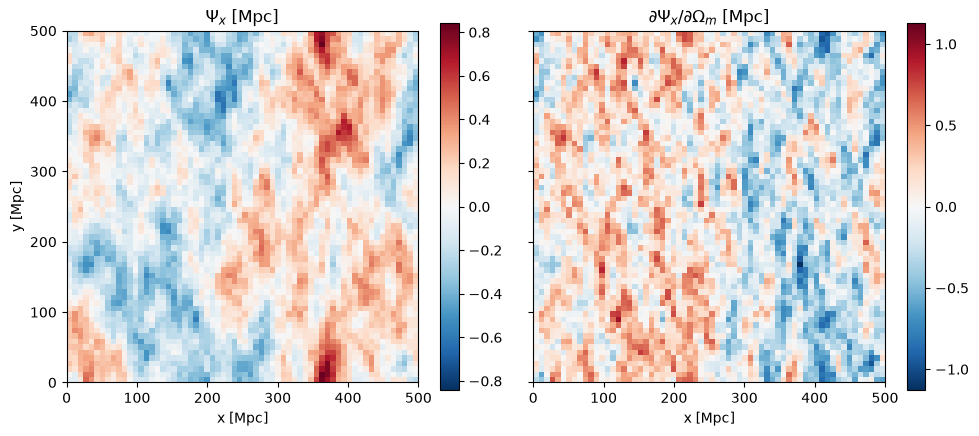

In [7]:
print(f"start: a = {A_INI:.5f}, z = {1.0 / A_INI - 1.0:.1f}")
print(f"rms displacement per axis: {jnp.sqrt(jnp.mean(displacement**2)):.3f} Mpc")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
fields = (displacement[0, :, :, 0], d_displacement[0, :, :, 0])
titles = (r"$\Psi_x$ [Mpc]", r"$\partial \Psi_x / \partial \Omega_m$ [Mpc]")
for ax, field, title in zip(axes, fields, titles):
    limit = float(jnp.abs(field).max())
    image = ax.imshow(
        np.asarray(field).T,
        origin="lower",
        extent=(0.0, BOX, 0.0, BOX),
        cmap="RdBu_r",
        vmin=-limit,
        vmax=limit,
    )
    fig.colorbar(image, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("x [Mpc]")
axes[0].set_ylabel("y [Mpc]")
fig.tight_layout()
plt.show()